# Apply RNN on a Custom NLP Case : Sentiment classification

In [16]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("dair-ai/emotion")
train_df = ds['train'].to_pandas()
val_df = ds['validation'].to_pandas()
test_df = ds['test'].to_pandas()

In [17]:
train_df.shape, val_df.shape, test_df.shape

((16000, 2), (2000, 2), (2000, 2))

In [18]:
train_df['label'].value_counts()

label
1    5362
0    4666
3    2159
4    1937
2    1304
5     572
Name: count, dtype: int64

In [19]:
# ── Data Cleaning ─────────────────────────────────────────────────────────────

print("Before cleaning:")
for name, df_ref in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"  {name:10s}: {df_ref.shape[0]} rows | {df_ref.duplicated().sum()} duplicates | {df_ref.isnull().sum().sum()} nulls")

train_df = train_df.drop_duplicates().dropna().reset_index(drop=True)
val_df   = val_df.drop_duplicates().dropna().reset_index(drop=True)
test_df  = test_df.drop_duplicates().dropna().reset_index(drop=True)

print("✅ After cleaning:")
for name, df_ref in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"  {name:10s}: {df_ref.shape[0]} rows | {df_ref.duplicated().sum()} duplicates | {df_ref.isnull().sum().sum()} nulls")


Before cleaning:
  Train     : 16000 rows | 1 duplicates | 0 nulls
  Validation: 2000 rows | 0 duplicates | 0 nulls
  Test      : 2000 rows | 0 duplicates | 0 nulls
✅ After cleaning:
  Train     : 15999 rows | 0 duplicates | 0 nulls
  Validation: 2000 rows | 0 duplicates | 0 nulls
  Test      : 2000 rows | 0 duplicates | 0 nulls


Plot data to see if distribution in train, validation and test data is equilibrate

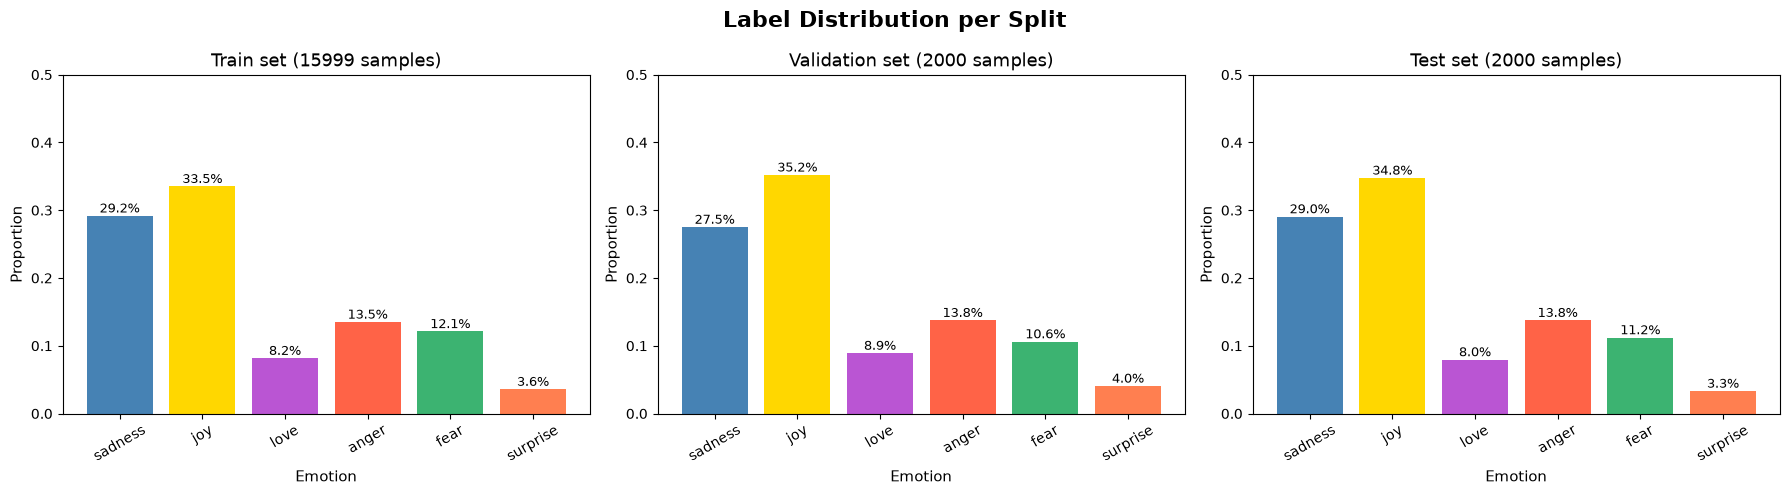

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Label names for the dair-ai/emotion dataset
label_names = {0: "sadness", 1: "joy", 2: "love", 3: "anger", 4: "fear", 5: "surprise"}
colors = ["steelblue", "gold", "mediumorchid", "tomato", "mediumseagreen", "coral"]

splits = [("Train", train_df), ("Validation", val_df), ("Test", test_df)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Label Distribution per Split", fontsize=16, fontweight="bold")

for ax, (name, df) in zip(axes, splits):
    counts = df["label"].value_counts().sort_index()
    labels = [label_names[i] for i in counts.index]
    ax.bar(labels, counts.values / len(df), color=colors)
    ax.set_title(f"{name} set ({len(df)} samples)", fontsize=13)
    ax.set_xlabel("Emotion", fontsize=11)
    ax.set_ylabel("Proportion", fontsize=11)
    ax.set_ylim(0, 0.5)
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(counts.values / len(df)):
        ax.text(i, v + 0.005, f"{v:.1%}", ha="center", fontsize=9)

plt.tight_layout()
plt.show()


It's okay. We have almost the same distribution everywhere.

## Data preprocessing

### Normalization

Normalizing our data: lower case, get rid of extra spaces, and url links. 

In [ ]:
import re

def normalize(data):
    normalized = []
    for i in data:
        i = i.lower()
        # get rid of urls
        i = re.sub(r'https?://\S+|www\.\S+', '', i)
        # get rid of numbers
        i = re.sub(r'\d+', '', i)
        # get rid of non words and extra spaces
        i = re.sub(r'\W', ' ', i)
        i = re.sub(r'\n', '', i)
        i = re.sub(r' +', ' ', i)
        i = re.sub(r'^ ', '', i)
        i = re.sub(r' $', '', i)
        normalized.append(i)
    return normalized

X_train = normalize(train_df["text"].tolist())
X_test = normalize(test_df["text"].tolist())
X_val = normalize(val_df["text"].tolist())
y_train = train_df['label'].values
y_test = test_df['label'].values
y_val = val_df['label'].values

<>:8: SyntaxWarning: invalid escape sequence '\S'
<>:10: SyntaxWarning: invalid escape sequence '\d'
<>:12: SyntaxWarning: invalid escape sequence '\W'
<>:8: SyntaxWarning: invalid escape sequence '\S'
<>:10: SyntaxWarning: invalid escape sequence '\d'
<>:12: SyntaxWarning: invalid escape sequence '\W'
/tmp/ipykernel_2532/1264300758.py:8: SyntaxWarning: invalid escape sequence '\S'
  i = re.sub('https?://\S+|www\.\S+', '', i)
/tmp/ipykernel_2532/1264300758.py:10: SyntaxWarning: invalid escape sequence '\d'
  i = re.sub('\d+', '', i)
/tmp/ipykernel_2532/1264300758.py:12: SyntaxWarning: invalid escape sequence '\W'
  i = re.sub('\W', ' ', i)


keep only 10000 words for our corpus

In [22]:
from tensorflow.keras.preprocessing.text import Tokenizer

max_vocab = 10000
tokenizer = Tokenizer(num_words=max_vocab)

#fit on strings
tokenizer.fit_on_texts(X_train)

In [23]:
# converts text to interge
X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)
X_val = tokenizer.texts_to_sequences(X_val)

In [24]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

X_train = pad_sequences(X_train, padding='post', maxlen=256)
X_test = pad_sequences(X_test, padding='post', maxlen=256)
X_val = pad_sequences(X_val, padding='post', maxlen=256)

## Training

In [25]:
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Bidirectional, Dense, Input
from tensorflow.keras import Sequential

model = Sequential([
    Input(shape=(256,)),
    Embedding(max_vocab, 128),  # output : batch x 256 (words) x 128 
    Bidirectional(LSTM(64, return_sequences=True)), # output : batch x 256 x 128 (64 forward + 64 backward)
    Bidirectional(LSTM(32)), # output : batch x 64 (32 forward + 32 backward)
    Dropout(0.5), # avoid overfitting | output : batch x 64
    Dense(6, activation='softmax') # softmax to ensure the probability of the 6 outputs is equal to 1
    # output : batch x 6
])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 256, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_6 (Bidirectional) │ (None, 256, 128)       │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_7 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,420,422 (5.42 MB)

 Trainable params: 1,420,422 (5.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam', 
    loss='sparse_categorical_crossentropy', 
    metrics=['accuracy']
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

model.fit(x=X_train, y=y_train, validation_data=(X_val, y_val), epochs=10, batch_size=32, callbacks=[early_stop], shuffle=True)